# Airbnb NYC 2019 — Exploratory Data Analysis

## Purpose

This notebook explores patterns and relationships in the Airbnb NYC 2019 dataset following the initial Data Understanding stage.

The analysis focuses on variables that may be relevant to the team's business question and later regression and clustering tasks.

The main areas to investigate are:

- price distribution;
- room types;
- neighbourhood and location;
- reviews;
- availability;
- minimum-night requirements;
- relationships between variables.

> This notebook explores the raw dataset. Final cleaning and preprocessing decisions will be implemented later in `03_data_preparation.ipynb`.

## 1. Load the Dataset

The original Airbnb NYC 2019 dataset is loaded from `data/raw/` for exploratory analysis.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/raw/AB_NYC_2019.csv")

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)

Dataset loaded successfully.
Dataset shape: (48895, 16)


### Quick Check

The dataset contains 48,895 Airbnb listings and 16 variables, which matches the dataset used at the time of  Data Understanding.

## 2. Price Distribution

### Question

How are Airbnb listing prices distributed, and are there unusually low or high prices that may affect later analysis and modelling?

Since `price` is the likely target variable for regression, it is important to understand its distribution before building the model.

### 2.1 Numerical Summary

First, we will review the main summary statistics for `price`, including the minimum, maximum, mean and quartiles.

In [2]:
df["price"].describe().round(2)

count    48895.00
mean       152.72
std        240.15
min          0.00
25%         69.00
50%        106.00
75%        175.00
max      10000.00
Name: price, dtype: float64

The median is also useful because it represents the middle price and is less affected by very high or low values.

In [3]:
median_price = df["price"].median()

print("Median price:", median_price)

Median price: 106.0


### Observation

The mean price is higher than the median price. This suggests that some higher-priced listings may be pulling the average upwards.

The price also ranges from $0 to $10,000, so the overall distribution should be examined visually before deciding whether any values require treatment.

### 2.2 Full Price Distribution

A histogram is used to see how listing prices are distributed across the complete dataset.

Each bar represents a range of prices, and the height of the bar shows approximately how many listings fall within that range.

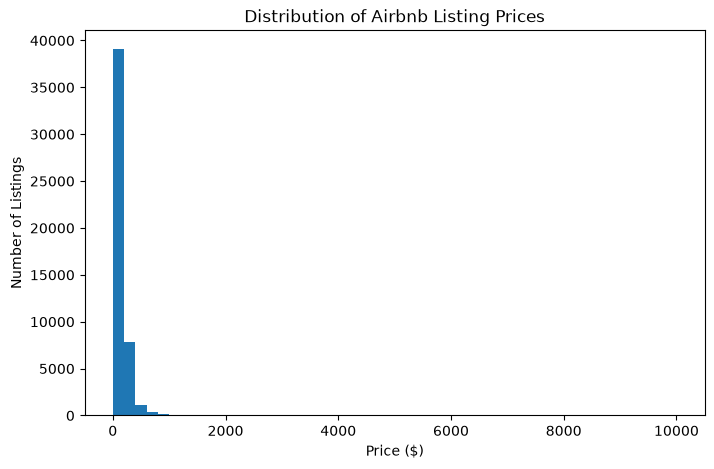

In [4]:
plt.figure(figsize=(8, 5))

plt.hist(df["price"], bins=50)

plt.title("Distribution of Airbnb Listing Prices")
plt.xlabel("Price ($)")
plt.ylabel("Number of Listings")

plt.savefig(
    "../outputs/figures/price_distribution_all.png",
    bbox_inches="tight"
)

plt.show()

### Observation

Most listings are concentrated in the lower price range, while a relatively small number of listings extend towards much higher prices.

The high-price values stretch the x-axis up to $10,000, making the main concentration of listings difficult to see clearly.

### 2.3 Closer View of the Price Distribution

The full histogram is affected by a small number of very high prices. To examine the majority of listings more clearly, I will calculate the 95th percentile of `price`.

The 95th percentile gives the price at or below which 95% of the listings fall. This is only used to create a clearer exploratory view; no records are removed from the original dataset.

In [5]:
price_95 = df["price"].quantile(0.95)

print("95th percentile price:", price_95)

95th percentile price: 355.0


To make the main price distribution easier to see, I will create a temporary view containing listings at or below the 95th percentile.

The original dataframe `df` remains unchanged.

In [6]:
price_below_95 = df[df["price"] <= price_95]

print("Original number of listings:", len(df))
print("Listings in 95th percentile view:", len(price_below_95))

Original number of listings: 48895
Listings in 95th percentile view: 46454


### 2.4 Price Distribution up to the 95th Percentile

The following histogram provides a closer view of the price range containing the majority of Airbnb listings.

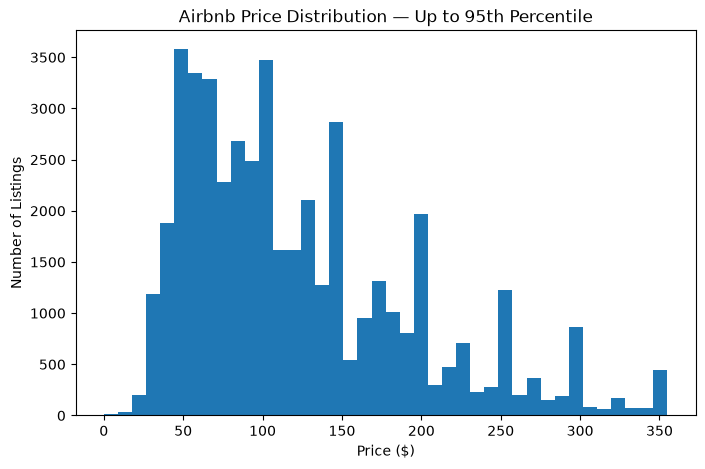

In [7]:
plt.figure(figsize=(8, 5))

plt.hist(price_below_95["price"], bins=40)

plt.title("Airbnb Price Distribution — Up to 95th Percentile")
plt.xlabel("Price ($)")
plt.ylabel("Number of Listings")

plt.savefig(
    "../outputs/figures/price_distribution_95pct.png",
    bbox_inches="tight"
)

plt.show()

### Observation

After limiting the visualisation to the 95th percentile, the main price distribution can be seen more clearly.

The 95th percentile price is $355, meaning 95% of listings are priced at or below this value. Viewing this range separately makes the main price pattern much clearer. Most listings remain concentrated toward lower prices, while the number of listings generally decreases as price increases, indicating a right-skewed distribution.

### 2.5 Price Distribution — Initial Finding

The two histograms provide different views of the same `price` variable:

- the first histogram shows the complete price range, including extreme values;
- the second histogram gives a clearer view of the majority of listings.

Together with the mean being higher than the median, the visualisations indicate that the price distribution is right-skewed.

The extreme and zero-price listings will not be removed during EDA. They remain data-quality issues to investigate before making a final decision during Data Preparation.

## 3. Room Type Analysis

### Question

What types of Airbnb accommodation are present in the dataset, how common is each room type, and do prices appear to differ between room types?

Room type may be relevant to the later regression analysis because the type of accommodation could be associated with listing price.

### 3.1 Room Type Categories

First, I will check the different room types in the dataset and count how many listings belong to each category.

In [8]:
df["room_type"].value_counts()

room_type
Entire home/apt    25409
Private room       22326
Shared room         1160
Name: count, dtype: int64

### Observation

The dataset contains three room-type categories. Entire homes/apartments and private rooms account for most listings, while shared rooms represent a much smaller part of the dataset.

### 3.2 Room Type Proportions

To make the room-type distribution easier to interpret, I will also calculate the percentage of listings represented by each category.

In [9]:
room_type_percentage = (
    df["room_type"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

room_type_percentage

room_type
Entire home/apt    51.97
Private room       45.66
Shared room         2.37
Name: proportion, dtype: float64

### 3.3 Distribution of Listings by Room Type

A bar chart is used to compare the number of Airbnb listings belonging to each room-type category.

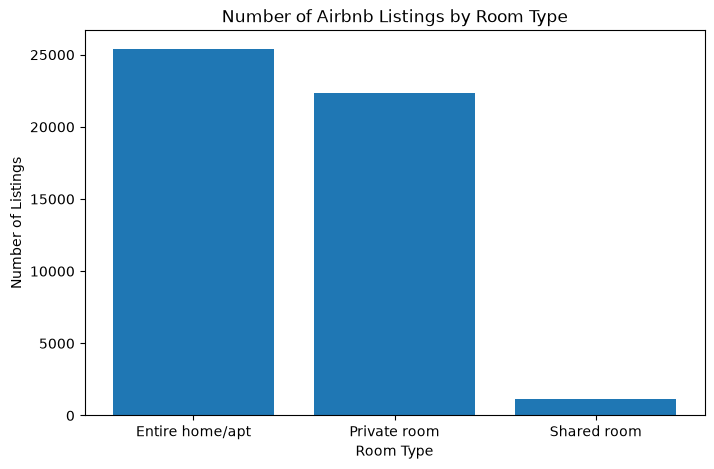

In [10]:
room_type_counts = df["room_type"].value_counts()

plt.figure(figsize=(8, 5))

plt.bar(
    room_type_counts.index,
    room_type_counts.values
)

plt.title("Number of Airbnb Listings by Room Type")
plt.xlabel("Room Type")
plt.ylabel("Number of Listings")

plt.savefig(
    "../outputs/figures/room_type_counts.png",
    bbox_inches="tight"
)

plt.show()

### Observation

Entire homes/apartments and private rooms make up most Airbnb listings in the dataset, while shared rooms are much less common.

This shows that the room-type categories are not equally represented in the NYC Airbnb market.

### 3.4 Price by Room Type

After examining how common each room type is, the next step is to investigate whether listing prices differ between room-type categories.

This may help determine whether `room_type` could be a useful feature for later price prediction.

In [11]:
df.groupby("room_type")["price"].agg(
    ["count", "mean", "median", "min", "max"]
).round(2)

,count,mean,median,min,max
room_type,,,,,
Entire home/apt,25409,211.79,160.0,0,10000
Private room,22326,89.78,70.0,0,10000
Shared room,1160,70.13,45.0,0,1800


### Observation

Prices differ noticeably across the three room-type categories.

Entire homes/apartments have the highest typical prices, with a median price of $160, compared with $70 for private rooms and $45 for shared rooms.

The mean price is higher than the median for each room type, suggesting that high-price listings affect the averages within these categories.

This initial pattern suggests that `room_type` may be useful when later building a model to predict listing prices. However, this is an exploratory finding and does not by itself show that room type causes the difference in price.

### 3.5 Median Price by Room Type

Because the price distribution contains extreme values, the median provides a useful way to compare the typical price across room types without being strongly influenced by a small number of very expensive listings.

In [12]:
median_price_by_room = (
    df.groupby("room_type")["price"]
    .median()
    .sort_values(ascending=False)
)

median_price_by_room

room_type
Entire home/apt    160.0
Private room        70.0
Shared room         45.0
Name: price, dtype: float64

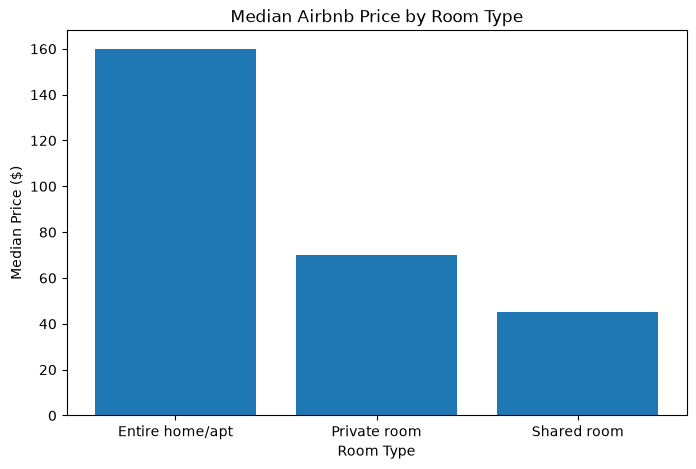

In [13]:
plt.figure(figsize=(8, 5))

plt.bar(
    median_price_by_room.index,
    median_price_by_room.values
)

plt.title("Median Airbnb Price by Room Type")
plt.xlabel("Room Type")
plt.ylabel("Median Price ($)")

plt.savefig(
    "../outputs/figures/median_price_by_room_type.png",
    bbox_inches="tight"
)

plt.show()

### Observation

The median price differs clearly between room types. Entire homes/apartments have the highest median price at $160, followed by private rooms at $70 and shared rooms at $45.

This provides further exploratory evidence that room type is associated with listing price and may therefore be worth considering as a feature in the later regression analysis.

### 3.6 Room Type — Initial Finding

Room type appears to be relevant to both the structure and pricing of the NYC Airbnb market.

Entire homes/apartments represent 51.97% of listings and private rooms represent 45.66%, while shared rooms account for only 2.37%. Typical prices also differ considerably between these categories, with median prices of $160, $70 and $45 respectively.

These findings suggest that `room_type` should be retained as a candidate variable for later analysis and price prediction. No modelling conclusion is made at this stage because EDA is being used to identify patterns rather than establish predictive performance.

### 3.7 Summary

I started by looking at price because that is likely to be our target for the regression part. The average price is about 153 but the median is 106, and the full histogram shows some very high-price listings going up to 10,000. When I looked only up to the 95th percentile, I found that 95% of listings are priced at 355 or below, so the price distribution is clearly skewed and we'll need to think about those extreme values during data preparation.

I then looked at room type. Around 52% of listings are entire homes or apartments, around 46% are private rooms and only about 2% are shared rooms. There also seems to be quite a strong price difference between them. The median is 160 for entire homes, 70 for private rooms and $45 for shared rooms. So at this stage I think room type is a useful candidate feature for our price prediction, but I'm treating that as an EDA finding rather than saying it definitely predicts price yet.

## 4. Neighbourhood / Location Analysis

### Question

How are Airbnb listings distributed across New York City's neighbourhood groups, and do listing prices appear to differ between locations?

Location may be relevant to the team's business question because Airbnb prices may vary across different parts of New York City.

This section first examines `neighbourhood_group`, which provides a broader location category, before considering whether more detailed neighbourhood information may be useful for later modelling.

### 4.1 Neighbourhood Groups

First, I will identify the neighbourhood groups represented in the dataset and count the number of listings in each group.

In [14]:
df["neighbourhood_group"].value_counts()

neighbourhood_group
Manhattan        21661
Brooklyn         20104
Queens            5666
Bronx             1091
Staten Island      373
Name: count, dtype: int64

### 4.2 Neighbourhood Group Proportions

To understand how the dataset is distributed geographically, I will calculate the percentage of listings belonging to each neighbourhood group.

In [15]:
neighbourhood_percentage = (
    df["neighbourhood_group"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

neighbourhood_percentage

neighbourhood_group
Manhattan        44.30
Brooklyn         41.12
Queens           11.59
Bronx             2.23
Staten Island     0.76
Name: proportion, dtype: float64

### 4.3 Distribution of Listings by Neighbourhood Group

A bar chart is used to compare the number of Airbnb listings across the five neighbourhood groups.

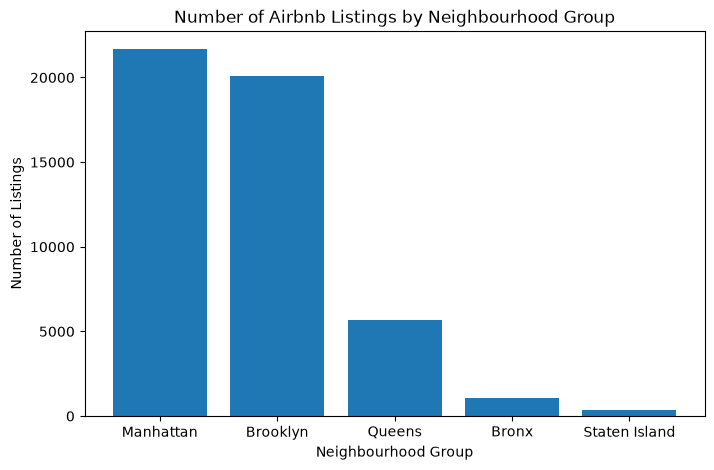

In [16]:
neighbourhood_counts = df["neighbourhood_group"].value_counts()

plt.figure(figsize=(8, 5))

plt.bar(
    neighbourhood_counts.index,
    neighbourhood_counts.values
)

plt.title("Number of Airbnb Listings by Neighbourhood Group")
plt.xlabel("Neighbourhood Group")
plt.ylabel("Number of Listings")

plt.savefig(
    "../outputs/figures/neighbourhood_group_counts.png",
    bbox_inches="tight"
)

plt.show()

### 4.4 Price by Neighbourhood Group

After examining how listings are distributed geographically, the next step is to compare listing prices across neighbourhood groups.

Because the overall price distribution contains extreme values, both the mean and median are examined. The median is particularly useful for comparing typical prices because it is less affected by a small number of very high-price listings.

In [17]:
df.groupby("neighbourhood_group")["price"].agg(
    ["count", "mean", "median", "min", "max"]
).round(2)

,count,mean,median,min,max
neighbourhood_group,,,,,
Bronx,1091,87.50,65.0,0,2500
Brooklyn,20104,124.38,90.0,0,10000
Manhattan,21661,196.88,150.0,0,10000
Queens,5666,99.52,75.0,10,10000
Staten Island,373,114.81,75.0,13,5000


### 4.5 Median Price by Neighbourhood Group

The median price is used to compare the typical listing price across neighbourhood groups while reducing the influence of extreme high-price listings.

In [18]:
median_price_by_neighbourhood_group = (
    df.groupby("neighbourhood_group")["price"]
    .median()
    .sort_values(ascending=False)
)

median_price_by_neighbourhood_group

neighbourhood_group
Manhattan        150.0
Brooklyn          90.0
Queens            75.0
Staten Island     75.0
Bronx             65.0
Name: price, dtype: float64

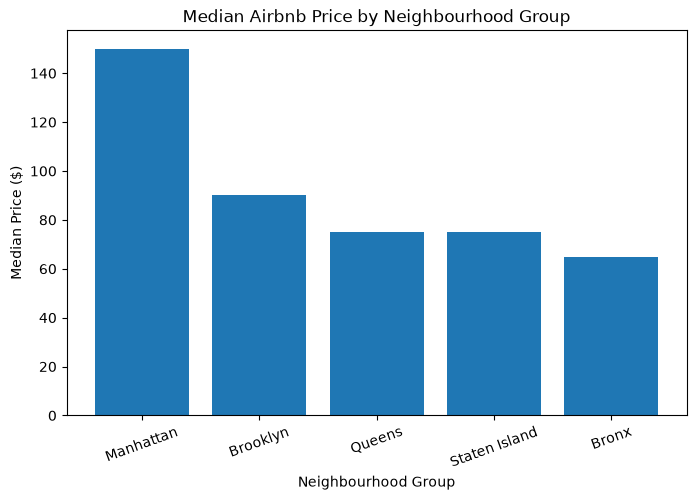

In [19]:
plt.figure(figsize=(8, 5))

plt.bar(
    median_price_by_neighbourhood_group.index,
    median_price_by_neighbourhood_group.values
)

plt.title("Median Airbnb Price by Neighbourhood Group")
plt.xlabel("Neighbourhood Group")
plt.ylabel("Median Price ($)")

plt.xticks(rotation=20)

plt.savefig(
    "../outputs/figures/median_price_by_neighbourhood_group.png",
    bbox_inches="tight"
)

plt.show()

### 4.6 Detailed Neighbourhoods

The `neighbourhood` variable provides more detailed location information than `neighbourhood_group`.

I will first check how many unique neighbourhoods are represented and identify the neighbourhoods with the largest number of listings. This helps determine whether the detailed location variable may be useful for later analysis and modelling.

In [20]:
print(
    "Number of unique neighbourhoods:",
    df["neighbourhood"].nunique()
)

df["neighbourhood"].value_counts().head(10)

Number of unique neighbourhoods: 221


neighbourhood
Williamsburg          3920
Bedford-Stuyvesant    3714
Harlem                2658
Bushwick              2465
Upper West Side       1971
Hell's Kitchen        1958
East Village          1853
Upper East Side       1798
Crown Heights         1564
Midtown               1545
Name: count, dtype: int64

### 4.7 Neighbourhood/Location - Initial Finding

The Airbnb listings in this dataset are not evenly distributed across New York City. Manhattan and Brooklyn contain most of the listings, representing 44.30% and 41.12% of the dataset respectively. Queens accounts for 11.59%, while the Bronx and Staten Island have much smaller shares.

Typical listing prices also differ across neighbourhood groups. Manhattan has the highest median price at 150, followed by Brooklyn at 90. Queens and Staten Island both have a median price of 75, while the Bronx has the lowest median price at 65.

The difference between the mean and median prices within the neighbourhood groups also suggests that some high-price listings are influencing the averages, which is consistent with the earlier finding that the overall price distribution is right-skewed.

The dataset also contains 221 individual neighbourhoods, showing that more detailed location information is available. However, using all neighbourhood categories may make later modelling more complex and will need to be considered during Data Preparation.

Overall, these exploratory findings suggest that location may be relevant to listing price. `neighbourhood_group`, and potentially the more detailed `neighbourhood` variable, should therefore be considered as candidate features for the later regression analysis. No conclusion about predictive performance is made at this stage.

## 5. EDA Summary and Next Step

The exploratory analysis identified several patterns that are relevant to the later modelling stage.

The `price` variable is right-skewed, with a median price of 106 compared with a mean of approximately 153. Most listings are within a much lower price range, while a relatively small number of very high-price listings extend up to 10,000. These extreme values should therefore be considered during Data Preparation rather than removed during EDA.

Room type also appears to be associated with price. Entire homes/apartments have a median price of $160, compared with 70 for private rooms and 45 for shared rooms.

Location shows a similar pattern. Manhattan has the highest median price at 150, while the other neighbourhood groups have lower typical prices. The dataset also contains 221 individual neighbourhoods, so the level of location detail used for modelling will need to be considered carefully.

Based on this EDA, `room_type` and location variables appear to be useful candidate features for later price prediction.

No records have been removed or transformed during this EDA stage.